# mTRF (Multivariate Temporal Response Function)

## Step 0: Setup
It is recommended by the author of eelbrain to have this section in a separate file (see https://eelbrain.readthedocs.io/en/stable/experiment.html#setting-up-the-analysis-code).
However, here we will try to put everything in the same file.

The file structure must follow the one indicated at https://eelbrain.readthedocs.io/en/stable/experiment.html#setting-up-the-file-structure):

```
Root                        /export/home/user/public/BodyLingual/Analysis/eelbrain
MEG directory                                                                     /meg
MEG subject                                                                           /sub-XX
trans-file                                                                                   /sub-XX-trans.fif
raw-file                                                                                     /sub-XX_track-raw.fif | /sub-XX_emptyroom-raw.fif
MRI directory                                                                     /mri
MRI subject                                                                           /sub-XX
```

### Imports

Note: to install trftools, use  `pip install https://github.com/christianbrodbeck/TRF-Tools/archive/main.zip`.

In [11]:
# mTRF modules
import eelbrain
from eelbrain.pipeline import *
from trftools.pipeline import *
from eelbrain import plot

# File manipulation
import os
import os.path as op
import json
from scipy.io import loadmat, wavfile  # Matlab files and WAV
from scipy.signal import hilbert, butter, filtfilt  # Envelope

# Moviepy
from moviepy.editor import VideoFileClip

# Date and time
from datetime import datetime as dt
from datetime import timedelta as td

# Get the username automatically
import getpass

# Numbers and statistics
import numpy as np
from scipy import stats as st
import statistics as stat

# Plotting
from matplotlib import pyplot as plt
from matplotlib.patches import ConnectionPatch
import seaborn as sns
sns.set_theme()

# Regex
import re

### Regions of interest for the source reconstruction

In [2]:
import mne

# Possible parcellations: "aparc", "aparc.a2009s", "aparc.DKTatlas"

user = getpass.getuser()
path_output = op.join('/export/home', user, 'public/BodyLingual/Analysis/')

subjects_dir = op.join(path_output, 'Freesurfer/')
os.environ["SUBJECTS_DIR"] = subjects_dir
# Load the FreeSurfer parcellation
labels = mne.read_labels_from_annot('sub-06', 'BA_exvivo', 'both')
for label in labels:
    print(label.name)

BA1_exvivo-lh
BA1_exvivo-rh
BA2_exvivo-lh
BA2_exvivo-rh
BA3a_exvivo-lh
BA3a_exvivo-rh
BA3b_exvivo-lh
BA3b_exvivo-rh
BA44_exvivo-lh
BA44_exvivo-rh
BA45_exvivo-lh
BA45_exvivo-rh
BA4a_exvivo-lh
BA4a_exvivo-rh
BA4p_exvivo-lh
BA4p_exvivo-rh
BA6_exvivo-lh
BA6_exvivo-rh
MT_exvivo-lh
MT_exvivo-rh
V1_exvivo-lh
V1_exvivo-rh
V2_exvivo-lh
V2_exvivo-rh
entorhinal_exvivo-lh
entorhinal_exvivo-rh
perirhinal_exvivo-lh
perirhinal_exvivo-rh
unknown-lh
unknown-rh


In [3]:
# Regions of interest for source reconstruction
STG =              ("transversetemporal", "superiortemporal")
LATERAL_TEMPORAL = STG + ("bankssts", "middletemporal", "inferiortemporal")
LATERAL_FRONTAL =  ("caudalmiddlefrontal", "frontalpole", 'parsopercularis', 'parsorbitalis', 'parstriangularis', 'precentral', 'rostralmiddlefrontal', 'superiorfrontal')
LATERAL_PARIETAL = ('postcentral', 'inferiorparietal', 'superiorparietal', 'supramarginal')
OTHER_TEMPORAL =   ('fusiform', 'temporalpole')
OTHER_MEDIAL =     ('cuneus', 'lateralorbitofrontal', 'medialorbitofrontal', 'paracentral', 'precuneus')
OCCIPITAL =        ('lateraloccipital', 'pericalcarine', 'lingual')
MEDIAL_TEMPORAL =  ('entorhinal', 'parahippocampal')
WHOLE_BRAIN =      LATERAL_TEMPORAL + MEDIAL_TEMPORAL + OTHER_TEMPORAL + LATERAL_FRONTAL + LATERAL_PARIETAL + OTHER_MEDIAL + OCCIPITAL

### Define the subjects

In [ ]:
selected_subjects = ["subject_06", "subject_07", "subject_09", "subject_10", "subject_11",
                     "subject_12", "subject_13", "subject_14", "subject_15", "subject_16",
                     "subject_17", "subject_18", "subject_19", "subject_20", "subject_21",
                     "subject_22", "subject_23", "subject_24", "subject_25", "subject_26",
                     "subject_27", "subject_28", "subject_29", "subject_30", "subject_31",
                     "subject_32", "subject_33", "subject_34", "subject_35", "subject_36"]

# Configuration
user = getpass.getuser()
path_data = op.join('/export/home', user, 'lab/MEG_EXPERIMENTS/BLCOMP/DATA/FIF/')

# Mat files
subjects_mat = {"subject_01": "10964.mat",
               " subject_02": "11153.mat",
                "subject_03": "7013.mat",
                "subject_04": "11041.mat",
                "subject_05": "",  # MAT missing
                "subject_06": "6560.mat",
                "subject_07": "10026.mat",
                "subject_08": "",  # MAT missing
                "subject_09": "8592.mat",
                "subject_10": "6358.mat",
                "subject_11": "7913.mat",
                "subject_12": "8500.mat",
                "subject_13": "11006.mat",
                "subject_14": "6165.mat",
                "subject_15": "9951.mat",
                "subject_16": "11519.mat",
                "subject_17": "11015.mat",
                "subject_18": "8759.mat",
                "subject_19": "8751.mat",
                "subject_20": "8113.mat",
                "subject_21": "10637.mat",
                "subject_22": "9231.mat",
                "subject_23": "9055.mat",
                "subject_24": "8978.mat",
                "subject_25": "3757.mat",
                "subject_26": "10114.mat",
                "subject_27": "11035.mat",
                "subject_28": "9535.mat",
                "subject_29": "8819.mat",
                "subject_30": "11066.mat",
                "subject_31": "7122.mat",
                "subject_32": "9800.mat",
                "subject_33": "9269.mat",
                "subject_34": "4209.mat",
                "subject_35": "11703.mat",
                "subject_36": "8891.mat"}

# Paths
path_main = op.join('/export', 'home', user, 'public', 'BodyLingual')
path_data = op.join(path_main, 'Analysis', 'derivatives', 'Preprocessing')
path_eelbrain = op.join(path_main, 'Analysis', 'eelbrain')
path_predictors = op.join(path_eelbrain, 'predictors')
path_mat_files = op.join(path_main, 'Scripts', 'MEG Analysis', 'MAT')
path_stimuli = op.join('/export', 'home', user, 'lab', 'MEG_EXPERIMENTS', 'BLCOMP', 'SCRIPTS', 'Stimuli')
path_wav = op.join(path_main, 'Stimuli')
path_figures = op.join(path_eelbrain, "figures")

# Subject class
class Subject(object):

    def __init__(self, subject):
        self.name = subject

        if subject not in subjects_mat.keys():
            raise Exception("Subject name not found.")
        
        self.number = subject[8:10]
        self.sub_name = "sub-" + self.number

        self.path_eelbrain = op.join(path_eelbrain, "meg", self.sub_name, f"{self.sub_name}_track-raw.fif")
        self.path_eelbrain_er = op.join(path_eelbrain, "meg", self.sub_name, f"{self.sub_name}_emptyroom-raw.fif")
        self.path_mat = op.join(path_mat_files, subjects_mat[self.name])

    def print_name(self):
        s = "#"
        print("")
        print(s * (len(self.name) + 10))
        print(s + s + "   " + self.name.upper() + "   " + s + s)
        print(s * (len(self.name) + 10))
        print("")

subjects = {}
for subject_name in selected_subjects:
    s = Subject(subject_name)
    subjects[s.sub_name] = s

## Step 1: Generate the predictors

### Generation

#### Audiovisual and Audio only

In [ ]:
def create_regressors(stimulus, mp4_audio_array, mp4_audio_freq, appendix, which="all"):
    """
    stimulus: e.g. AO_M_XX_001
    mp4_audio_array: the audio file
    mp4_audio_freq: the audio file frequency
    appendix: appendix to add to all the files (e.g. _audionoise, _audio, _noise)
    which: "all" or a list of predictors (e.g. ["gammatone", "gammatone-1"])
    """

    print("\tSaving as WAV...")
    wavfile.write(op.join(path_wav, stimulus[:11] + appendix + ".wav"), mp4_audio_freq, mp4_audio_array) #.astype(np.int16))

    print("\tOpening the WAV...")
    wav = eelbrain.load.wav(op.join(path_wav, stimulus[:11] + appendix + ".wav"), name=stimulus[:11], backend="scipy")

    print("\tGenerating the gammatone...")
    gammatone = eelbrain.gammatone_bank(wav = wav,          # Sound input
                                        f_min = 80,         # Lower frequency cutoff
                                        f_max = 15000,      # Upper frequency cutoff
                                        n = 128,            # Number of filter channels
                                        tstep = 0.001,      # Time step size in the output
                                        location = 'left')  # Location of the output relative to the input time axis
    
    if which == "all" or "gammatone" in which:
        path_gammatone = op.join(path_predictors, f"{stimulus[:11]}~gammatone" + appendix + ".pickle")
        print(f"\tSaving the gammatone as {path_gammatone}...")
        eelbrain.save.pickle(gammatone, path_gammatone)

    # Apply a log transform to approximate peripheral auditory processing
    print("\tGenerating gammatone-1...")
    gammatone_log = (gammatone + 1).log()
    if which == "all" or "gammatone-1" in which:
        path_gammatone_log = op.join(path_predictors, f"{stimulus[:11]}~gammatone" + appendix + "-1.pickle")
        print(f"\tSaving the gammatone as {path_gammatone_log}...")
        eelbrain.save.pickle(gammatone_log.sum('frequency'), path_gammatone_log)

    # Apply the edge detector model to generate an acoustic onset spectrogram
    print("\tGenerating gammatone-on-1...")
    gammatone_onset = eelbrain.edge_detector(gammatone_log, c=30)
    if which == "all" or "gammatone-on-1" in which:
        path_gammatone_onset = op.join(path_predictors, f"{stimulus[:11]}~gammatone" + appendix + "-on-1.pickle")
        print(f"\tSaving the gammatone as {path_gammatone_onset}...")
        eelbrain.save.pickle(gammatone_onset.sum('frequency'), path_gammatone_onset)

    # 8-band version of the two predictors
    if which == "all" or "gammatone-8" in which:
        print("\tGenerating gammatone-8...")
        gammatone_log_8 = gammatone_log.bin(nbins=8, func="sum", dim="frequency")
        path_gammatone_log_8 = op.join(path_predictors, f"{stimulus[:11]}~gammatone" + appendix + "-8.pickle")
        print(f"\tSaving the gammatone as {path_gammatone_log_8}...")
        eelbrain.save.pickle(gammatone_log_8, path_gammatone_log_8)

    if which == "all" or "gammatone-on-8" in which:
        print("\tGenerating gammatone-on-8...")
        gammatone_onset_8 = gammatone_onset.bin(nbins=8, func="sum", dim="frequency")
        path_gammatone_onset_8 = op.join(path_predictors, f"{stimulus[:11]}~gammatone" + appendix + "-on-8.pickle")
        print(f"\tSaving the gammatone as {gammatone_onset_8}...")
        eelbrain.save.pickle(gammatone_onset_8, path_gammatone_onset_8)

    # Powerlaw scale
    if which == "all" or "gammatone-pow-8" in which:
        print("\tGenerating gammatone-pow-8...")
        gammatone_pow = gammatone ** 0.6
        x = gammatone_pow.bin(nbins=8, func='sum', dim='frequency')
        path_gammatone_pow = op.join(path_predictors, f"{stimulus[:11]}~gammatone" + appendix + "-pow-8.pickle")
        print(f"\tSaving the gammatone as {path_gammatone_pow}...")
        eelbrain.save.pickle(x, path_gammatone_pow)

    # Envelope
    if which == "all" or "envelope" in which:
        envelope = np.abs(hilbert(mp4_audio_array))
        b, a = butter(2, [0.1, 49], "band", fs=mp4_audio_freq)
        envelope_filt = filtfilt(b, a, envelope, padtype="constant", padlen=None)
        envelope_res = np.interp(np.arange(0, len(envelope_filt)/mp4_audio_freq, 0.001), np.arange(0, len(envelope_filt))/mp4_audio_freq, envelope_filt)
        envelope_filt_res = filtfilt(b, a, envelope_res, padtype="constant", padlen=None)
        time_dim = eelbrain.UTS(0, 0.001, np.size(envelope_filt_res))
        ndvar_envelope = eelbrain.NDVar(envelope_filt_res, (time_dim), name="envelope")
        path_envelope = op.join(path_predictors, f"{stimulus[:11]}~envelope" + appendix + ".pickle")
        print(f"\tSaving the envelope as {path_envelope}...")
        eelbrain.save.pickle(ndvar_envelope, path_envelope)

In [ ]:
stimuli_audio = []
stimuli_audio += os.listdir(op.join(path_stimuli, "AO_M_XX"))
stimuli_audio += os.listdir(op.join(path_stimuli, "AO_U_XX"))
stimuli_audio += os.listdir(op.join(path_stimuli, "AV_M_BD"))
stimuli_audio += os.listdir(op.join(path_stimuli, "AV_U_BD"))
stimuli_audio += os.listdir(op.join(path_stimuli, "AV_X_SC"))
stimuli_audio += os.listdir(op.join(path_stimuli, "AV_X_SK"))

with open("video_to_original.txt", "r") as f:
    video_to_original = {line.split("\t")[0]: line.split("\t")[1] for line in f.read().split("\n")}

for stimulus in stimuli_audio:
    print(stimulus)
    
    # Audio + noise
    print("\tGetting the audio with noise from the video...")
    path_video = op.join(path_stimuli, stimulus[:7], stimulus)
    mp4_video = VideoFileClip(path_video)
    mp4_audio = mp4_video.audio
    mp4_audio_freq = mp4_audio.fps
    mp4_audio_array = np.array(list(mp4_audio.iter_frames()))

    print("\tSaving as WAV...")
    wavfile.write(op.join(path_wav, stimulus[:11] + ".wav"), mp4_audio_freq, mp4_audio_array) #mp4_audio_array.astype(np.int16))

    if mp4_audio_array.ndim > 1:
        print("\tTurning to mono...")
        mp4_audio_array = np.mean(mp4_audio_array, axis=1)

    create_regressors(stimulus, mp4_audio_array, mp4_audio_freq, "_audionoise")

    # Audio clear
    print("\tGetting the audio without noise from the video...")
    path_video = op.join(path_main, "Recordings", "Audiovisual", "03_Normalized_audiovisual", "Normalized_bodies", video_to_original[stimulus] + ".mp4")
    mp4_video = VideoFileClip(path_video)
    mp4_audio = mp4_video.audio
    mp4_audio_freq = mp4_audio.fps
    mp4_audio_array = np.array(list(mp4_audio.iter_frames()))

    if mp4_audio_array.ndim > 1:
        print("\tTurning to mono...")
        mp4_audio_array = np.mean(mp4_audio_array, axis=1)

    create_regressors(stimulus, mp4_audio_array, mp4_audio_freq, "_audio")

    # Noise only
    print("\tGetting noise the right length...")
    path_noise = op.join(path_wav, "Noise.wav")
    audio_freq, audio_array = wavfile.read(path_noise)

    if audio_array.ndim > 1:
        print("\tTurning to mono...")
        audio_array = np.mean(audio_array, axis=1)

    # We want the noise to be the duration of the audio
    duration_mp4_audio = np.size(mp4_audio_array) / mp4_audio_freq
    audio_array = audio_array[:int(duration_mp4_audio * audio_freq)]

    create_regressors(stimulus, audio_array, audio_freq, "_noise")

#### Video only

In [ ]:
import shutil

stimuli_matches = {"VO_M_BD": "AV_M_BD", "VO_U_BD": "AV_U_BD", "VO_X_SC": "AV_X_SC", "VO_X_SK": "AV_X_SK"}
predictors = [("gammatone", ""), ("gammatone", "-1"), ("gammatone", "-on-1"), ("gammatone", "-8"), ("gammatone", "-on-8"), ("gammatone", "-pow-8"), ("envelope", "")]
for stimulus in stimuli_matches:
    print(stimulus)
    for component in ["audio", "noise", "audionoise"]:
        print("\t" + component)
        for predictor in predictors:
            print("\t\t" + predictor[0] + predictor[1])
            for i in range(1, 82):
                original_predictor_path = op.join(path_predictors, f"{stimuli_matches[stimulus]}_{str(i).zfill(3)}~{predictor[0]}_{component}{predictor[1]}.pickle")
                new_predictor_path = op.join(path_predictors, f"{stimulus}_{str(i).zfill(3)}~{predictor[0]}_{component}{predictor[1]}.pickle")
                # print(original_predictor_path)
                # print(new_predictor_path)
                # print(op.exists(original_predictor_path))
                # print(op.exists(new_predictor_path))
                if op.exists(original_predictor_path) and not op.exists(new_predictor_path):
                    shutil.copy(original_predictor_path, new_predictor_path)

### Observation

(Scalar('frequency', [80, ..., 14543.2] (128), 'Hz'), UTS(0.0, 0.001, 77140))
(Scalar('frequency', [80, ..., 14543.2] (128), 'Hz'), UTS(0.0, 0.001, 77140))
(Scalar('frequency', [80, ..., 14543.2] (128), 'Hz'), UTS(0.0, 0.001, 77160))


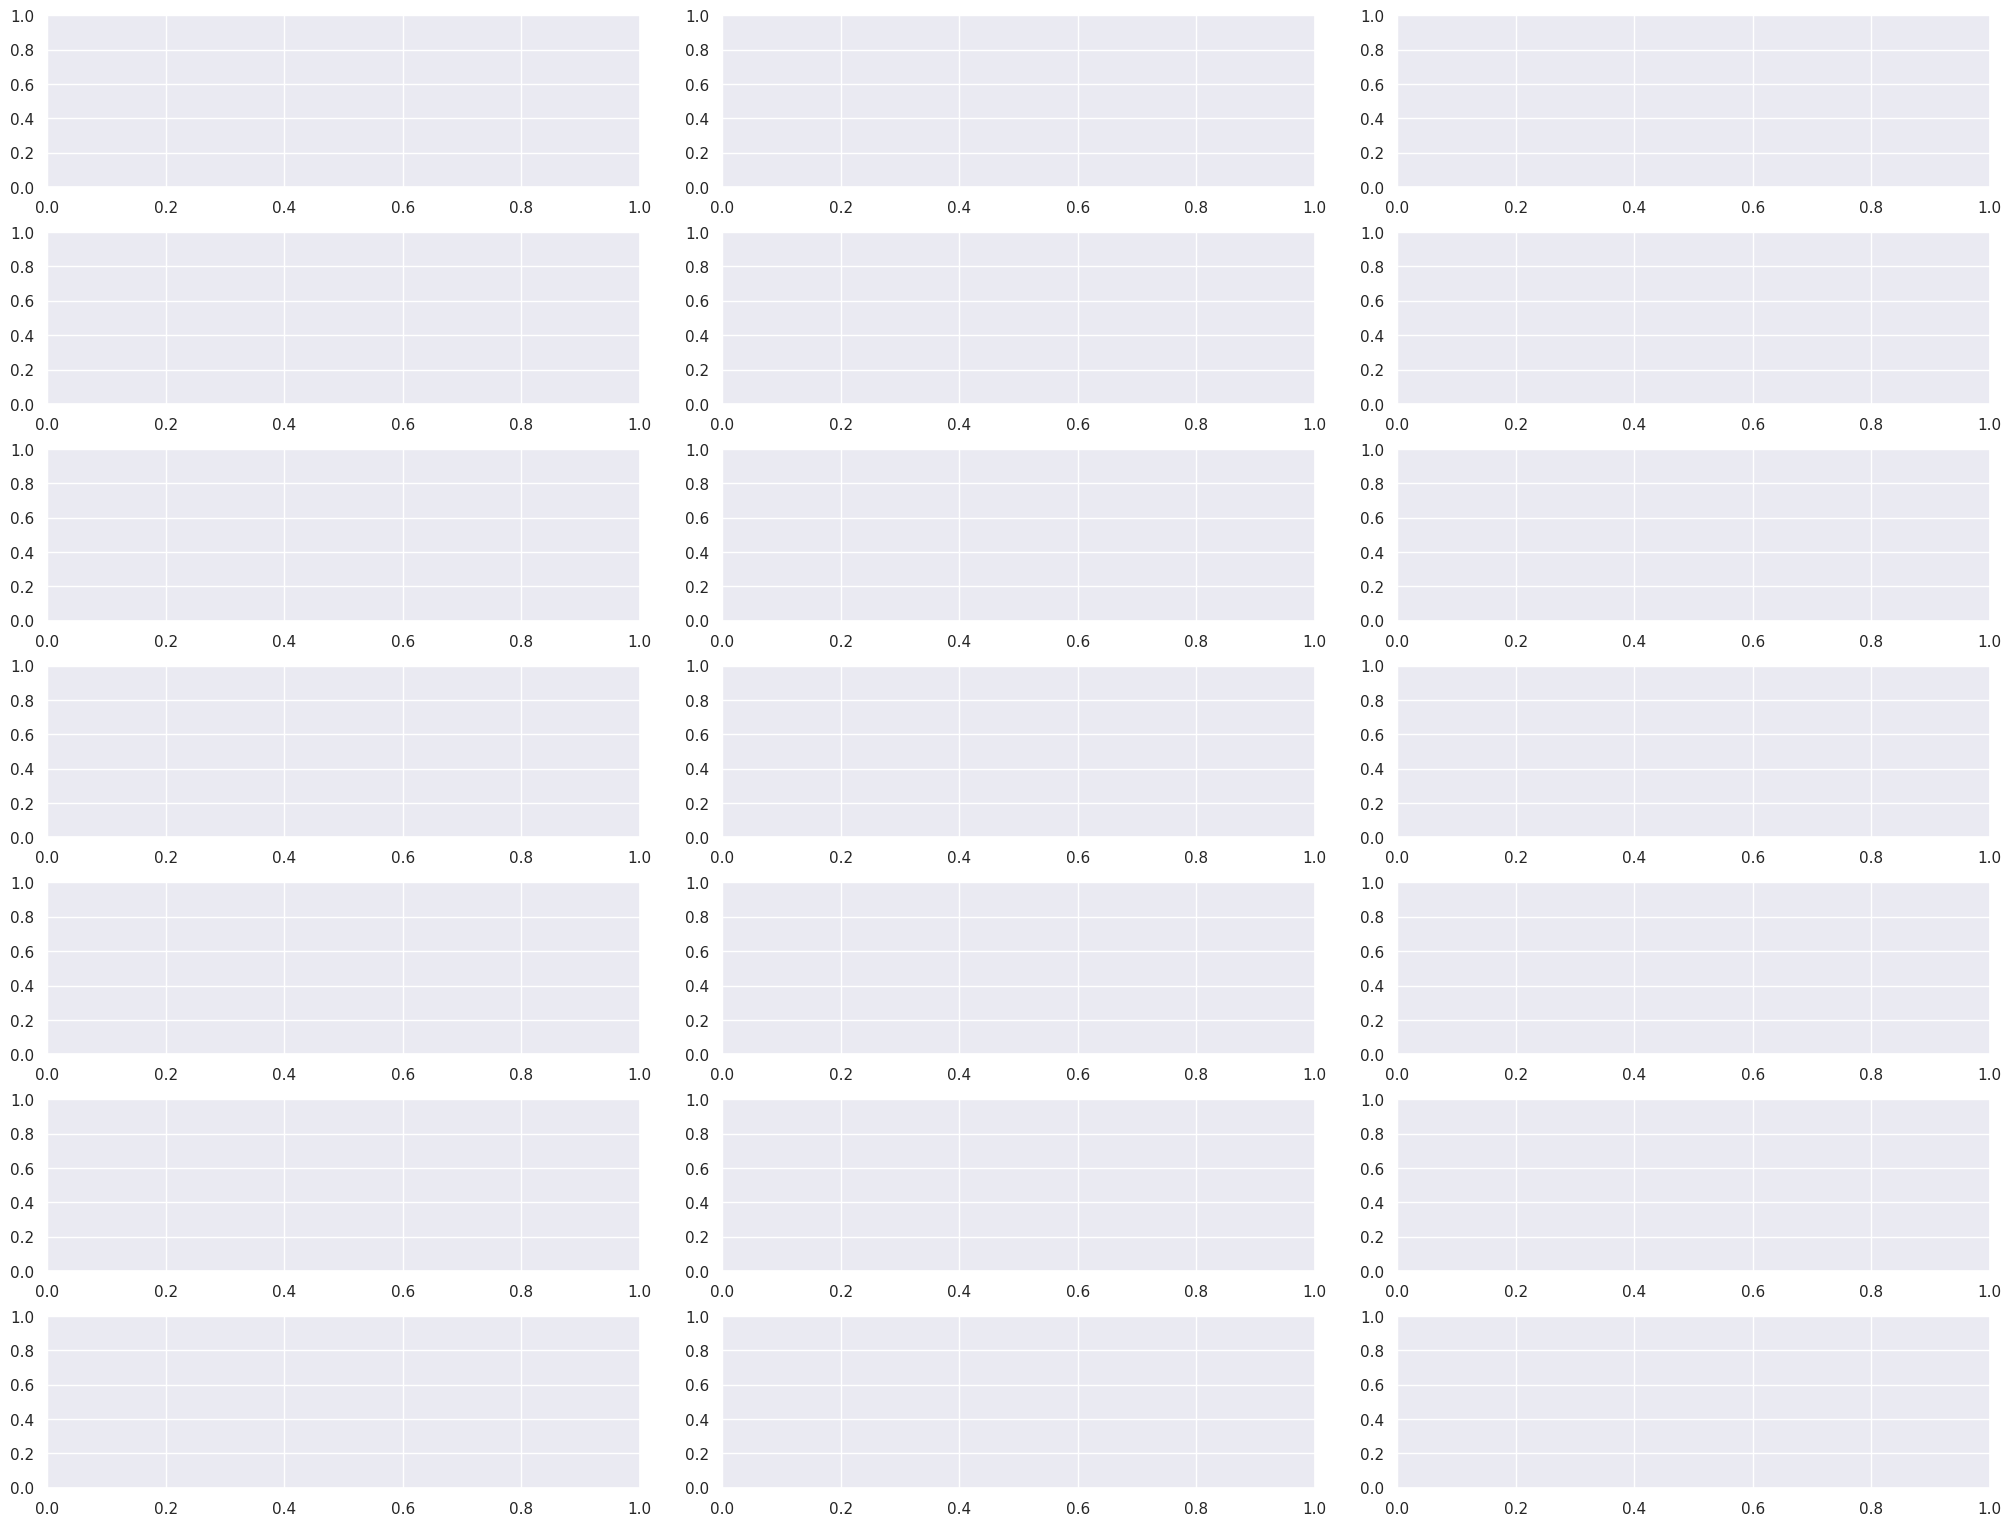

In [ ]:
stimulus = "AO_M_XX_002"

predictors = [("gammatone", ""), ("gammatone", "-1"), ("gammatone", "-on-1"), ("gammatone", "-8"), ("gammatone", "-on-8"), ("gammatone", "-pow-8"), ("envelope", "")]

colors = {"audio": "#478ae8", "noise": "#e03131", "audionoise": "#9131e0"}
fig, axes = plot.subplots(len(predictors), 3)
fig.set_figwidth(20)

for component, c in zip(["audio", "noise", "audionoise"], [0, 1, 2]):
    for predictor_cat, p in zip(predictors, range(len(predictors))):
        predictor = eelbrain.load.unpickle(op.join(path_predictors, f"{stimulus}~" + predictor_cat[0] + "_" + component + predictor_cat[1] + ".pickle"))
        break
        # print(op.join(path_predictors, f"{stimulus}~" + predictor_cat[0] + "_" + component + predictor_cat[1] + ".pickle"))
        # ax = plt.subplot(5, 3, (p + c * 5) + 1)
        if len(np.shape(predictor)) > 1:
            data = predictor.get_data()  # shape: (frequency, time)
            frequencies = predictor.get_dim('frequency').values  # frequency axis
            times = predictor.get_dim('time').times  # time axis in seconds
            axes[p][c].imshow(data, aspect='auto', origin='lower', extent=[times[0], times[-1], frequencies[0], frequencies[-1]], cmap='magma_r')
            axes[p][c].set_title(predictor_cat[0] + " " + component + " " + predictor_cat[1])
            # pl = plot.UTS(predictor.mean("frequency"), , colors=colors[component], axes=axes[p][c])
        else:
            pl = plot.UTS(predictor, axtitle=predictor_cat[0] + " " + component + " " + predictor_cat[1], colors=colors[component], axes=axes[p][c])

fig.set_constrained_layout(True)

## Step 2: Create the TRFExperiment object

In [ ]:
# Definition of the eelbrain structure
class BodyLingual(TRFExperiment):
    
    # Adding info about the conditions (eelbrain function redefinition)
    def label_events(self, ds):

        # If the session is emptyroom, we return it directly
        if ds.info['session'] != 'track':
            return ds
        
        subject_name = ds.info['subject']
        print(subject_name)

        # Get the conditions
        mat_contents = loadmat(subjects[subject_name].path_mat)  # Load the MAT file
        mat_videos = mat_contents["data"][0][0][3][0]  # Get the array containing the videos for each trial

        videos = []
        for i in range(len(mat_videos)):
            videos.append(mat_videos[i][0][0][0])

        # Conditions
        modalities = []
        masked = []
        body_mappings = []
        cartoons = []
        videos_new = []

        for video in videos:
             modalities += [video.split("_")[0], None, None]
             masked += [video.split("_")[1], None, None]
             body_mappings += [video.split("_")[2], None, None]
             cartoons += [video.split("_")[3].split(".")[0], None, None]
             videos_new += [video[:11], None, None]

        if subject_name == "sub-10":
            modalities = modalities[6:]
            masked = masked[6:]
            body_mappings = body_mappings[6:]
            cartoons = cartoons[6:]
            videos_new = videos_new[6:]

        ds.add(eelbrain.Factor(modalities, "modality"), replace = True)
        ds.add(eelbrain.Factor(masked, "masked"), replace = True)
        ds.add(eelbrain.Factor(body_mappings, "body_mapping"), replace = True)
        ds.add(eelbrain.Factor(cartoons, "cartoon"), replace = True)
        ds.add(eelbrain.Factor(videos_new, "video"), replace = True)

        return ds
    
    # Directories
    data_dir = "meg"  # The name of the folder from which to fetch the MEG/EEG Data
    mri_dir = "mri"  # The name of the folder from which to fetch the MRI data
    cache_dir = "eelbrain-cache"  # The name of the folder that will contain the cache data
    subject_re = r'sub-(\d{2})$'  # The pattern to match to find the subjects (here, "sub-XX")

    # Experiment parameters
    sessions = ("track", "emptyroom")  # Sessions of interest 
    visits = ("",)  # Visits (set if more than one)
    stim_channel = "STI101"  # Channel containing the triggers
    stim_var = "video"  # TRF-Tools specific, defines the name of the column containing the stimuli in the event dataset (which are in turn used to select the proper gammatones)
    
    # Verbosity parameters
    auto_delete_cache = "auto"  # "auto" (default, deletes outdated files), "ask" (ask whether to delete or raise an error), or "debug" (prompt with debug options)
    screen_log_level = "debug"  # Can be "critical" (least verbose), "error", "warning", "info" (default), "debug" (most verbose) or "notset"

    # Pre-processing pipeline: each entry in `raw` specifies one processing step. The first parameter
    # of each entry specifies the source (another processing step or 'raw' for raw input data).
    raw = {
        "raw":  RawSource(connectivity = "none"),  # Connectivity needs to be None. If auto, an error will appear about missing channels...
        "1-20": RawFilter("raw", 1, 20, cache = True),  # Band-pass filter 1-20 Hz, no need to go higher for mTRF
    }

    # Variables determine how event triggers are mapped to meaningful labels. Events are represented
    # as data-table in which each row corresponds to one event (i.e., one trigger). Each variable
    # defined here adds one column in that data-table, assigning a label or value to each event.
    variables = {
        # "stimulus":     LabelVar("trigger", {(10, 11, 20, 21, 22, 23, 30, 31, 32, 33): "placeholder"}),
        "modality":     LabelVar("trigger", {(10, 11): "AO", (20, 21, 22, 23): "VO", (30, 31, 32, 33): "AV"}),
        "masked":       LabelVar("trigger", {(10, 20, 30): "U", (11, 21, 31): "M", (22, 23, 32, 33): "X"}),
        "body_mapping": LabelVar("trigger", {(20, 21, 30, 31): "BD", (22, 32): "SK", (23, 33): "SC", (10, 11): "XX"}),
        "cartoon":      LabelVar("trigger", {(10, 11, 20, 21, 22, 23, 30, 31, 32, 33): "placeholder"}),
        "video":        LabelVar("trigger", {(10, 11, 20, 21, 22, 23, 30, 31, 32, 33): "placeholder"}),
    }

    # Epochs specify how to extract time-locked data segments ("epochs") from the continuous data.
    epochs = {
        "av":        PrimaryEpoch("track", "modality == 'AV'", tmax = "SOA", samplingrate = 50),
        "av_bd":     SecondaryEpoch("av", "body_mapping == 'BD'", samplingrate = 50),
        "av_sk":     SecondaryEpoch("av", "body_mapping == 'SK'", samplingrate = 50),
        "av_sc":     SecondaryEpoch("av", "body_mapping == 'SC'", samplingrate = 50),
        "av_bd_m":   SecondaryEpoch("av_bd", "masked == 'M'", samplingrate = 50),
        "av_bd_u":   SecondaryEpoch("av_bd", "masked == 'U'", samplingrate = 50),
        "ao":        PrimaryEpoch("track", "modality == 'AO'", tmax = "SOA", samplingrate = 50),
        "ao_m":      SecondaryEpoch("ao", "masked == 'M'", samplingrate = 50),
        "ao_u":      SecondaryEpoch("ao", "masked == 'U'", samplingrate = 50),
        "vo":        PrimaryEpoch("track", "modality == 'VO'", tmax = "SOA", samplingrate = 50),
        "vo_bd":     SecondaryEpoch("vo", "body_mapping == 'BD'", samplingrate = 50),
        "vo_sk":     SecondaryEpoch("vo", "body_mapping == 'SK'", samplingrate = 50),
        "vo_sc":     SecondaryEpoch("vo", "body_mapping == 'SC'", samplingrate = 50),
        "vo_bd_u":   SecondaryEpoch("vo_bd", "masked == 'M'", samplingrate = 50),
        "vo_bd_m":   SecondaryEpoch("vo_bd", "masked == 'U'", samplingrate = 50)
    }

    # Groups of subjects (can be ignored if there is only one group).
    groups = {
        "all_subjects": Group([subjects[sub].sub_name for sub in subjects]),  # "all" is always implicitely defined.
    }

    # Parcellations: determines how the brain surface is divided into regions.
    parcs = {
        "superiortemporal":  SubParc("aparc", STG),
        "lateraltemporal":   SubParc("aparc", LATERAL_TEMPORAL),
        "occipital":         SubParc("aparc", OCCIPITAL),
        "wholebrain":        SubParc("aparc", WHOLE_BRAIN),
        "lateralparietal":   SubParc("aparc", LATERAL_PARIETAL),
        "inferiorparietal":  SubParc("aparc", "inferiorparietal"),
        "supramarginal":     SubParc("aparc", "supramarginal"),
        # to up-scale:
        "stg_to_temporal":   SubParc("aparc", sorted(set(LATERAL_TEMPORAL).difference(STG))),
        "stg_to_wholebrain": SubParc("aparc", sorted(set(WHOLE_BRAIN).difference(STG))),
    }   

    # TRF-Tools specific: Predictors. No need to put variants; gammatone, gammatone-1 and gammatone-8 will be covered by gammatone.
    predictors = {
        "gammatone_audionoise":        FilePredictor(resample = "bin"),
        "gammatone_audio":             FilePredictor(resample = "bin"),
        "gammatone_noise":             FilePredictor(resample = "bin"),
        "envelope_audionoise":         FilePredictor(resample = "bin"),
        "envelope_audio":              FilePredictor(resample = "bin"),
        "envelope_noise":              FilePredictor(resample = "bin"),
    }
    
    # TRF-Tools specific: Models are shortcuts to group predictors
    models = {}
    
    # Default settings for experiment analysis parameters
    defaults = {
        'cov' : 'emptyroom',  # Method for correcting the sensor covariance
    }  

### Create the experiment instance
Initialize the pipeline object, by scanning the provided directory for the required data (see introduction).

In [ ]:
e = BodyLingual(path_eelbrain)
# e.invalidate()  # Removes cache whenever the contents of a predictor file are changed (changes in predictor files are not automatically detected).
e.set(raw = '1-20')  # Applies a band pass filter. Can take "subject" as a parameter to specify a single subject. 

### Show the subjects

In [ ]:
e.show_subjects("all")  # Prints the subjects to check that everything is in order.

### Plot the first 10 seconds of data
(Doesn't work without having wxPython installed -> which cannot be installed without GTK+3)

In [ ]:
y = e.load_raw(ndvar = True)
p = plot.TopoButterfly(y, xlim = 10, w = 0)

### Show the epochs

In [ ]:
e.load_epochs(subjects = None)  # If None, loads for the first subject only. A specific subject can be specified (e.g. "sub-06") or "all".

### Common TRF parameters

In [ ]:
PARAMETERS = dict(raw = '1-20',               # Band-pass filter
                  samplingrate = 50,          # Resampling rate
                  tstart = -0.100,            # Start of the TRF (s)
                  tstop = 0.600,              # End of the TRF (s)
                  error = 'l2',               # Noise reduction. Could be l1 if noisier data, as it diminishes the influence of high amplitude moments
                  partitions = -5,            # The minus specifies to concatenate all the epochs first and then do the partition (good for epochs of unequal length)
                  cv = True,                  # Use cross-validation
                  inv = 'fixed-6-MNE-0',      # What inverse solution to use for source localization
                  # mask = 'superiortemporal',  # Parcellation to mask source space data
                  data = 'source',            # Analyze source-space data ("source", default) or sensor-space data ("meg")
                  filter_x = 'continuous',    # Only filter the continuous regressors with the same filter as the MEG signal
                  selective_stopping = 1)     # Selective stopping for avoiding overfitting to more "salient" regressors

## Step 3: Run the TRFs

### Per stimulus type

In [ ]:
class TRF(object):
    def __init__(self, predictor_type, variant, epoch, mask, stimulus_type, pretty_name, trf):
        self.predictor_type = predictor_type
        self.variant = variant
        self.epoch = epoch
        self.mask = mask
        self.stimulus_type = stimulus_type
        self.pretty_name = pretty_name
        self.trf = trf

def plot_results(trfs, plot_superimposed=False, save_figure=True):
    if plot_superimposed:
        fig, axes = plt.subplots(figsize=(12, 3))
        sup = "sup"
    else:
        fig, axes = plt.subplots(len(trfs), 1, sharex=True, sharey=True, figsize=(12, 3 * len(trfs)))
        sup = "diff"


    colors = {"audio": "#478ae8", "noise": "#e03131", "audionoise": "#9131e0"}
    variant_normalized = trfs[0].variant.replace("-", "_")

    to_plot = []
    if "frequency" in [dim.name for dim in trfs[0].trf[predictor_type + "_" + trfs[0].stimulus_type + variant_normalized].dims]:
        for trf in trfs:
            to_plot.append(trf.trf[predictor_type + "_" + trf.stimulus_type + variant_normalized].mean("frequency").mean("source"))
    else:
        for trf in trfs:
            to_plot.append(trf.trf[predictor_type + "_" + trf.stimulus_type + variant_normalized].mean("source"))

    max_abs_value = np.max([np.abs(np.mean(single_plot.x, 0)) for single_plot in to_plot])

    if plot_superimposed:
        for i in range(len(trfs)):
            eelbrain_plt = plot.UTS(to_plot[i], colors=colors[trfs[i].stimulus_type], axes=axes)
        axes.set_ylim(-1.05 * max_abs_value, 1.05 * max_abs_value)
        axes.legend(labels=[trf.pretty_name for trf in trfs])
        axes.set_title(f"{trfs[0].mask.title()} {trfs[0].epoch.upper()} {predictor_type + trfs[0].variant} ({subject})")

    else:
        for i, ax in enumerate(axes):
            eelbrain_plt = plot.UTS(to_plot[i], colors=colors[trfs[i].stimulus_type], axes=ax)
            ax.set_ylim(-1.05 * max_abs_value, 1.05 * max_abs_value)
            ax.set_title(trfs[i].pretty_name)
            if i != len(trfs) - 1:
                ax.tick_params("x", labelbottom=False)
                ax.set_xlabel("")
            else:
                ax.set_xlabel("Time (ms)")
            ax.set_ylabel(None)

        fig.suptitle(f"{trfs[0].mask.title()} {trfs[0].epoch.upper()} {predictor_type + trfs[0].variant} ({subject})", y=1.02)
        fig.text(0.04, 0.5, 'Current estimate (normalized)', va='center', rotation='vertical')

        plt.subplots_adjust(top=0.95, hspace=0.2)

    if save_figure:
        path_figures_predictor = op.join(path_figures, predictor_type + variant, mask)
        os.makedirs(path_figures_predictor, exist_ok=True)
        plt.savefig(op.join(path_figures_predictor, subject + "_" + predictor_type + trfs[0].variant + "_" + trfs[0].epoch + "_" + trfs[0].mask + "_" + sup + ".png"), bbox_inches="tight")

    plt.show()
    plt.close()

#### Single TRF

In [ ]:
subject = "all_subjects"
predictor_type = "gammatone"  # gammatone, envelope, or baseline
variant = "-8" # "", "-1", "-on-1", "-8", "-on-8", "-pow-8" (only if gammatone)
epoch = "av"
mask = "superiortemporal"
make = True  # Whether to create the trf in cache

# x: predictor variables (if more than one, join with "+")
trf_an = e.load_trfs(subject = subject, x = predictor_type + "_audionoise" + variant, epoch = epoch, make = make, mask = mask, **PARAMETERS)
trf_a = e.load_trfs(subject = subject, x = predictor_type + "_audio" + variant, epoch = epoch, make = make, mask = mask, **PARAMETERS)
trf_n = e.load_trfs(subject = subject, x = predictor_type + "_noise" + variant, epoch = epoch, make = make, mask = mask, **PARAMETERS)

trf_an = TRF(predictor_type, variant, epoch, mask, "audionoise", "Audio + Noise", trf_an)
trf_a = TRF(predictor_type, variant, epoch, mask, "audio", "Audio", trf_a)
trf_n = TRF(predictor_type, variant, epoch, mask, "noise", "Noise", trf_n)

plot_results([trf_an, trf_a, trf_n], False, True)
plot_results([trf_an, trf_a, trf_n], True, True)

#### Batch

In [ ]:
subject = "all_subjects"
predictors = [("gammatone", "-8"), ("gammatone", "-on-8"), ("gammatone", "-pow-8"), ("envelope", "")]
epochs = ["av", "av_bd", "av_sk", "av_sc", "av_bd_m", "av_bd_u", "ao", "ao_m", "ao_u", "vo", "vo_bd", "vo_sk", "vo_sc", "vo_bd_u", "vo_bd_m"]
masks = ["superiortemporal", "lateraltemporal", "occipital", "inferiorparietal", "supramarginal", "wholebrain"]
stimuli_types = ["audionoise", "audio", "noise"]
pretty_names = {"audionoise": "Audio + Noise", "audio": "Audio", "noise": "Noise"}
make = True  # Whether to create the trf in cache

i = 1
min_i = 316

for mask in masks:
    for epoch in epochs:
        for predictor_type, variant in predictors:
            if i >= min_i:
                t_begin = dt.now()
                print("TRF #" + str(i) + " of " + str(len(predictors) * len(epochs) * len(masks)))
                print("\tPredictor: " + predictor_type + variant)
                print("\tEpoch: " + epoch)
                print("\tMask: " + mask)
                trfs = []
                for stimulus_type in stimuli_types:
                    print("\t\tStimulus type: " + stimulus_type)
                    trf = e.load_trfs(subject = subject, x = predictor_type + "_" + stimulus_type + variant, epoch = epoch, make = make, mask = mask, **PARAMETERS)
                    trfs.append(TRF(predictor_type, variant, epoch, mask, stimulus_type, pretty_names[stimulus_type], trf))
                plot_results(trfs, False, True)
                plot_results(trfs, True, True)

                print(f"Full TRF computed in {dt.now() - t_begin}")

            i += 1

### Per condition

In [ ]:
class TRF(object):
    def __init__(self, predictor_type, variant, epoch, mask, stimulus_type, pretty_name_stimulus_type, pretty_name_epoch, trf):
        self.predictor_type = predictor_type
        self.variant = variant
        self.epoch = epoch
        self.mask = mask
        self.stimulus_type = stimulus_type
        self.pretty_name_stimulus_type = pretty_name_stimulus_type
        self.pretty_name_epoch = pretty_name_epoch
        self.trf = trf

def plot_results_epochs(trfs, conds=None, plot_superimposed=False, save_figure=True, add_title_figure=""):
    if plot_superimposed:
        fig, axes = plt.subplots(figsize=(12, 3))
        sup = "sup"
    else:
        fig, axes = plt.subplots(6, 3, sharex=True, sharey=True, figsize=(36, 18))
        sup = "diff"

    colors = {"av": "#275317", "av_bd": "#8caa2c", "av_bd_m": "#13f901", "av_bd_u": "#608d49", "av_sk": "#4ea72e", "av_sc": "#2aac5f",
              "vo": "#363aca", "vo_bd": "#70b9da", "vo_bd_m": "#1ff18d", "vo_bd_u": "#21d5ff", "vo_sk": "#6d90dd", "vo_sc": "#7a6ddd",
              "ao": "#b08600", "ao_m": "#ffc000", "ao_u": "#f39547"}

    variant_normalized = trfs[0].variant.replace("-", "_")

    if conds is None:
        conds = list(colors.keys())

    if add_title_figure != "":
        add_title_figure = "_" + add_title_figure

    to_plot = []
    epochs = []
    pretty_names = []
    if "frequency" in [dim.name for dim in trfs[0].trf[predictor_type + "_" + trfs[0].stimulus_type + variant_normalized].dims]:
        for trf in trfs:
            if trf.epoch in conds:
                to_plot.append(trf.trf[predictor_type + "_" + trf.stimulus_type + variant_normalized].mean("frequency").mean("source"))
                epochs.append(trf.epoch)
                pretty_names.append(trf.pretty_name_epoch)
    else:
        for trf in trfs:
            if trf.epoch in conds:
                to_plot.append(trf.trf[predictor_type + "_" + trf.stimulus_type + variant_normalized].mean("source"))
                epochs.append(trf.epoch)
                pretty_names.append(trf.pretty_name_epoch)

    max_abs_value = np.max([np.abs(np.mean(single_plot.x, 0)) for single_plot in to_plot])

    if plot_superimposed:
        for i in range(len(to_plot)):
            eelbrain_plt = plot.UTS(to_plot[i], colors=colors[epochs[i]], axes=axes)
        axes.set_ylim(-1.05 * max_abs_value, 1.05 * max_abs_value)
        axes.legend(labels=pretty_names, loc="center left", bbox_to_anchor=(1, 0.5))
        axes.set_title(f"{trfs[0].mask.title()} {trfs[0].pretty_name_stimulus_type} {predictor_type + trfs[0].variant} ({subject})")

    else:
        for i in range(len(trfs)):
            for i in range(len(to_plot)):
                ax = axes[i % 6][i // 6]
                eelbrain_plt = plot.UTS(to_plot[i], colors=colors[epochs[i]], axes=ax)
                ax.set_ylim(-1.05 * max_abs_value, 1.05 * max_abs_value)
                ax.set_title(pretty_names[i])
                if i not in (5, 11, 14):
                    ax.tick_params("x", labelbottom=False)
                    ax.set_xlabel("")
                else:
                    ax.tick_params("x", labelbottom=True)
                    ax.set_xlabel("Time (ms)")
                ax.set_ylabel(None)

        fig.delaxes(axes[3][2])
        fig.delaxes(axes[4][2])
        fig.delaxes(axes[5][2])

        fig.suptitle(f"{trfs[0].mask.title()} {trfs[0].pretty_name_stimulus_type} {predictor_type + trfs[0].variant} ({subject})", y=1.02)
        fig.text(0.04, 0.5, 'Current estimate (normalized)', va='center', rotation='vertical')
        # fig.text(0.5, 0.96, 'Time (ms)', ha='center')

        plt.subplots_adjust(top=0.95, hspace=0.2)

    if save_figure:
        path_figures_predictor = op.join(path_figures, predictor_type + variant, mask, "conditions")
        os.makedirs(path_figures_predictor, exist_ok=True)
        plt.savefig(op.join(path_figures_predictor, subject + "_" + predictor_type + trfs[0].variant + "_" + trfs[0].stimulus_type + "_" + trfs[0].mask + "_" + sup + add_title_figure + ".png"), bbox_inches="tight")

    plt.show()

#### Single TRF

In [ ]:
subject = "all_subjects"
predictor_type = "gammatone"  # gammatone, envelope, or baseline
variant = "-8" # "", "-1", "-on-1", "-8", "-on-8", "-pow-8" (only if gammatone)
mask = "superiortemporal"
make = True  # Whether to create the trf in cache

# x: predictor variables (if more than one, join with "+")
epochs = ["av", "av_bd", "av_sk", "av_sc", "av_bd_m", "av_bd_u", "vo", "vo_bd", "vo_sk", "vo_sc", "vo_bd_m", "vo_bd_u", "ao", "ao_m", "ao_u"]
pretty_names_epochs = {"av": "Audiovisual", "av_bd": "Audiovisual (body)", "av_sk": "Audiovisual (skeleton)", "av_sc": "Audiovisual (scrambled)",
                       "av_bd_m": "Audiovisual (body, masked)", "av_bd_u": "Audiovisual (body, unmasked)",
                       "ao": "Audio only", "ao_m": "Audio only (masked)", "ao_u": "Audio only (unmasked)",
                       "vo": "Video only", "vo_bd": "Video only (body)", "vo_sk": "Video only (skeleton)", "vo_sc": "Video only (scrambled)",
                       "vo_bd_u": "Video only (body, masked)", "vo_bd_m": "Video only (body, unmasked)"}
trfs = []
for epoch in epochs:
    trf = e.load_trfs(subject = subject, x = predictor_type + "_audionoise" + variant, epoch = epoch, make = make, mask = mask, **PARAMETERS)
    trfs.append(TRF(predictor_type, variant, epoch, mask, "audionoise", "Audio + Noise", pretty_names_epochs[epoch], trf))

plot_results_epochs(trfs, None, False, True, "all")
plot_results_epochs(trfs, None, True, True, "all")
plot_results_epochs(trfs, ["av", "ao", "vo"], True, True, "modalities")
plot_results_epochs(trfs, ["av_bd_m", "av_bd_u", "av_sk", "av_sc", "vo_bd_m", "vo_bd_u", "vo_sk", "vo_sc", "ao_m", "ao_u"], True, True, "conditions")

#### Batch

In [ ]:
subject = "all_subjects"
predictors = [("gammatone", "-8"), ("gammatone", "-on-8"), ("gammatone", "-pow-8"), ("envelope", "")]
epochs = ["av", "av_bd", "av_sk", "av_sc", "av_bd_m", "av_bd_u", "vo", "vo_bd", "vo_sk", "vo_sc", "vo_bd_m", "vo_bd_u", "ao", "ao_m", "ao_u"]
masks = ["superiortemporal", "lateraltemporal", "occipital", "inferiorparietal", "supramarginal", "wholebrain"]
stimuli_types = ["audionoise", "audio", "noise"]
pretty_names_stimuli_types = {"audionoise": "Audio + Noise", "audio": "Audio", "noise": "Noise"}
pretty_names_epochs = {"av": "Audiovisual", "av_bd": "Audiovisual (body)", "av_sk": "Audiovisual (skeleton)", "av_sc": "Audiovisual (scrambled)",
                       "av_bd_m": "Audiovisual (body, masked)", "av_bd_u": "Audiovisual (body, unmasked)",
                       "ao": "Audio only", "ao_m": "Audio only (masked)", "ao_u": "Audio only (unmasked)",
                       "vo": "Video only", "vo_bd": "Video only (body)", "vo_sk": "Video only (skeleton)", "vo_sc": "Video only (scrambled)",
                       "vo_bd_u": "Video only (body, masked)", "vo_bd_m": "Video only (body, unmasked)"}
make = True

i = 1

for mask in masks:
    for predictor_type, variant in predictors:
        for stimulus_type in stimuli_types:
            t_begin = dt.now()
            print("TRF #" + str(i) + " of " + str(len(predictors) * len(epochs) * len(masks)))
            print("\tPredictor: " + predictor_type + variant)
            print("\tMask: " + mask)
            print("\tStimulus type: " + stimulus_type)
            trfs = []
            for epoch in epochs:
                print("\t\tEpoch: " + epoch)
                trf = e.load_trfs(subject = subject, x = predictor_type + "_" + stimulus_type + variant, epoch = epoch, make = make, mask = mask, **PARAMETERS)
                trfs.append(TRF(predictor_type, variant, epoch, mask, stimulus_type, pretty_names_stimuli_types[stimulus_type], pretty_names_epochs[epoch], trf))
            plot_results_epochs(trfs, None, False, True, "all")
            plot_results_epochs(trfs, None, True, True, "all")
            plot_results_epochs(trfs, ["av", "ao", "vo"], True, True, "modalities")
            plot_results_epochs(trfs, ["av_bd_m", "av_bd_u", "av_sk", "av_sc", "vo_bd_m", "vo_bd_u", "vo_sk", "vo_sc", "ao_m", "ao_u"], True, True, "conditions")

            print(f"Full TRF computed in {dt.now() - t_begin}")
            i += len(epochs)
            break

### Per predictor

In [ ]:
class TRF(object):
    def __init__(self, predictor_type, variant, epoch, mask, stimulus_type, pretty_name_stimulus_type, pretty_name_epoch, trf):
        self.predictor_type = predictor_type
        self.variant = variant
        self.variant_normalized = variant.replace("-", "_")
        self.predictor = (predictor_type, variant)
        self.epoch = epoch
        self.mask = mask
        self.stimulus_type = stimulus_type
        self.pretty_name_stimulus_type = pretty_name_stimulus_type
        self.pretty_name_epoch = pretty_name_epoch
        self.trf = trf

def plot_results_predictors(trfs, predictors=None, plot_superimposed=False, save_figure=True, add_title_figure=""):
    if plot_superimposed:
        fig, axes = plt.subplots(figsize=(12, 3))
        sup = "sup"
    else:
        fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(18, 6))
        sup = "diff"

    colors = {("gammatone", "-8"): "#dd2020",
              ("gammatone", "-on-8"): "#77bb10",
              ("gammatone", "-pow-8"): "#2020aa",
              ("envelope", ""): "#dd20dd"}

    if predictors is None:
        predictors = list(colors.keys())

    if add_title_figure != "":
        add_title_figure = "_" + add_title_figure

    to_plot = []
    graphs = []
    pretty_names = []
    for trf in trfs:
        if "frequency" in [dim.name for dim in trf.trf[trf.predictor_type + "_" + trf.stimulus_type + trf.variant.replace("-", "_")].dims]:
            if trf.predictor in predictors:
                to_plot.append(trf.trf[trf.predictor_type + "_" + trf.stimulus_type + trf.variant.replace("-", "_")].mean("frequency").mean("source"))
                graphs.append(trf.predictor)
                pretty_names.append(trf.predictor_type + trf.variant)
        else:
            if trf.predictor in predictors:
                to_plot.append(trf.trf[trf.predictor_type + "_" + trf.stimulus_type + trf.variant.replace("-", "_")].mean("source"))
                graphs.append(trf.predictor)
                pretty_names.append(trf.predictor_type + trf.variant)

    max_abs_value = np.max([np.abs(np.mean(single_plot.x, 0)) for single_plot in to_plot])

    if plot_superimposed:
        for i in range(len(to_plot)):
            eelbrain_plt = plot.UTS(to_plot[i], colors=colors[graphs[i]], axes=axes)
        axes.set_ylim(-1.05 * max_abs_value, 1.05 * max_abs_value)
        axes.legend(labels=pretty_names, loc="center left", bbox_to_anchor=(1, 0.5))
        axes.set_title(f"{trfs[0].mask.title()} {trfs[0].pretty_name_stimulus_type} {trfs[0].pretty_name_epoch} ({subject})")

    else:
        for i in range(len(trfs)):
            for i in range(len(to_plot)):
                ax = axes[i % 2][i // 2]
                eelbrain_plt = plot.UTS(to_plot[i], colors=colors[graphs[i]], axes=ax)
                ax.set_ylim(-1.05 * max_abs_value, 1.05 * max_abs_value)
                ax.set_title(pretty_names[i])
                if i not in (1, 3):
                    ax.tick_params("x", labelbottom=False)
                    ax.set_xlabel("")
                else:
                    ax.tick_params("x", labelbottom=True)
                    ax.set_xlabel("Time (ms)")
                ax.set_ylabel(None)

        fig.suptitle(f"{trfs[0].mask.title()} {trfs[0].pretty_name_stimulus_type} {trfs[0].pretty_name_epoch} ({subject})", y=1.02)
        fig.text(0.04, 0.5, 'Current estimate (normalized)', va='center', rotation='vertical')
        # fig.text(0.5, 0.96, 'Time (ms)', ha='center')

        plt.subplots_adjust(top=0.95, hspace=0.2)

    if save_figure:
        path_figures_comparison = op.join(path_figures, "comparison", mask)
        os.makedirs(path_figures_comparison, exist_ok=True)
        plt.savefig(op.join(path_figures_comparison, subject + "_" + trfs[0].stimulus_type + "_" + trfs[0].epoch + "_" + trfs[0].mask + "_" + sup + add_title_figure + ".png"), bbox_inches="tight")

    plt.show()

#### Single TRF

In [ ]:
plot_results_predictors(trfs, None, False, True)
plot_results_predictors(trfs, None, True, True)

In [ ]:
subject = "all_subjects"
epoch = "av"
mask = "superiortemporal"
make = True  # Whether to create the trf in cache

# x: predictor variables (if more than one, join with "+")
predictors = [("gammatone", "-8"), ("gammatone", "-on-8"), ("gammatone", "-pow-8"), ("envelope", "")]
pretty_names_epochs = {"av": "Audiovisual", "av_bd": "Audiovisual (body)", "av_sk": "Audiovisual (skeleton)", "av_sc": "Audiovisual (scrambled)",
                       "av_bd_m": "Audiovisual (body, masked)", "av_bd_u": "Audiovisual (body, unmasked)",
                       "ao": "Audio only", "ao_m": "Audio only (masked)", "ao_u": "Audio only (unmasked)",
                       "vo": "Video only", "vo_bd": "Video only (body)", "vo_sk": "Video only (skeleton)", "vo_sc": "Video only (scrambled)",
                       "vo_bd_u": "Video only (body, masked)", "vo_bd_m": "Video only (body, unmasked)"}
trfs = []
for predictor_type, variant in predictors:
    print(predictor_type + variant)
    trf = e.load_trfs(subject = subject, x = predictor_type + "_audionoise" + variant, epoch = epoch, make = make, mask = mask, **PARAMETERS)
    trfs.append(TRF(predictor_type, variant, epoch, mask, "audionoise", "Audio + Noise", pretty_names_epochs[epoch], trf))

plot_results_predictors(trfs, None, False, True)
plot_results_predictors(trfs, None, True, True)

#### Batch

In [ ]:
subject = "all_subjects"
predictors = [("gammatone", "-8"), ("gammatone", "-on-8"), ("gammatone", "-pow-8"), ("envelope", "")]
epochs = ["av", "av_bd", "av_sk", "av_sc", "av_bd_m", "av_bd_u", "vo", "vo_bd", "vo_sk", "vo_sc", "vo_bd_m", "vo_bd_u", "ao", "ao_m", "ao_u"]
masks = ["superiortemporal", "lateraltemporal", "occipital", "inferiorparietal", "supramarginal", "wholebrain"]
stimuli_types = ["audionoise", "audio", "noise"]
pretty_names_stimuli_types = {"audionoise": "Audio + Noise", "audio": "Audio", "noise": "Noise"}
pretty_names_epochs = {"av": "Audiovisual", "av_bd": "Audiovisual (body)", "av_sk": "Audiovisual (skeleton)", "av_sc": "Audiovisual (scrambled)",
                       "av_bd_m": "Audiovisual (body, masked)", "av_bd_u": "Audiovisual (body, unmasked)",
                       "ao": "Audio only", "ao_m": "Audio only (masked)", "ao_u": "Audio only (unmasked)",
                       "vo": "Video only", "vo_bd": "Video only (body)", "vo_sk": "Video only (skeleton)", "vo_sc": "Video only (scrambled)",
                       "vo_bd_u": "Video only (body, masked)", "vo_bd_m": "Video only (body, unmasked)"}
make = True

i = 262

for mask in masks:
    for stimulus_type in stimuli_types:
        for epoch in epochs:
            t_begin = dt.now()
            print("TRF #" + str(i) + " of " + str(len(stimuli_types) * len(epochs) * len(masks)))
            print("\tMask: " + mask)
            print("\tStimulus type: " + stimulus_type)
            print("\tEpoch: " + epoch)
            trfs = []
            for predictor_type, variant in predictors:
                print("\t\tPredictor: " + predictor_type + variant)
                trf = e.load_trfs(subject = subject, x = predictor_type + "_" + stimulus_type + variant, epoch = epoch, make = make, mask = mask, **PARAMETERS)
                trfs.append(TRF(predictor_type, variant, epoch, mask, stimulus_type, pretty_names_stimuli_types[stimulus_type], pretty_names_epochs[epoch], trf))
            plot_results_predictors(trfs, None, False, True)
            plot_results_predictors(trfs, None, True, True)

            print(f"Full TRF computed in {dt.now() - t_begin}")
            i += 1